## Setup

In [1]:
%pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install --upgrade -q botocore boto3

Note: you may need to restart the kernel to use updated packages.


In [3]:
import boto3

In [4]:
sess = boto3.Session(profile_name='rasripa+vs-poc-Admin')
bedrock = sess.client('bedrock', 'us-west-2')
response = bedrock.list_foundation_models()
print(response.get('modelSummaries')) 

[{'modelArn': 'arn:aws:bedrock:us-west-2::foundation-model/amazon.titan-tg1-large', 'modelId': 'amazon.titan-tg1-large', 'modelName': 'Titan Text Large', 'providerName': 'Amazon', 'inputModalities': ['TEXT'], 'outputModalities': ['TEXT'], 'responseStreamingSupported': True, 'customizationsSupported': [], 'inferenceTypesSupported': ['ON_DEMAND'], 'modelLifecycle': {'status': 'ACTIVE'}}, {'modelArn': 'arn:aws:bedrock:us-west-2::foundation-model/amazon.titan-embed-g1-text-02', 'modelId': 'amazon.titan-embed-g1-text-02', 'modelName': 'Titan Text Embeddings v2', 'providerName': 'Amazon', 'inputModalities': ['TEXT'], 'outputModalities': ['EMBEDDING'], 'customizationsSupported': [], 'inferenceTypesSupported': ['ON_DEMAND'], 'modelLifecycle': {'status': 'ACTIVE'}}, {'modelArn': 'arn:aws:bedrock:us-west-2::foundation-model/amazon.titan-text-lite-v1:0:4k', 'modelId': 'amazon.titan-text-lite-v1:0:4k', 'modelName': 'Titan Text G1 - Lite', 'providerName': 'Amazon', 'inputModalities': ['TEXT'], 'out

In [5]:
bedrock = sess.client('bedrock-runtime', 'us-west-2')

In [6]:
s3 = sess.resource('s3')

In [7]:
def initialise_bedrock():
    global bedrock
    if bedrock is None:
        sess = boto3.Session(profile_name='rasripa+vs-poc-Admin')
        bedrock = sess.client('bedrock-runtime', 'us-west-2')

In [8]:
def initialise_s3():
    global s3
    if s3 is None:
        sess = boto3.Session(profile_name='rasripa+vs-poc-Admin')
        s3 = sess.resource('s3')

## Get products into dynamodb

In [ ]:
!aws s3 cp --profile  s3://transferbucket-89719/FlipkartProd/flipkart_com-ecommerce_sample.csv .

In [ ]:
%pip install --quiet tqdm

In [ ]:
import csv
import json
from decimal import Decimal
from tqdm import tqdm
import boto3
from boto3.dynamodb.types import TypeSerializer

In [ ]:
#Initialize the DynamoDB resource
dynamodb = sess.resource('dynamodb')

In [ ]:
def is_json(value):
    try:
        json.loads(value)
        return True
    except:
        return False

In [ ]:
def extract_lists(row, column):
    list_string = row.get(column, "").strip('[]').strip('"')
    if column == "product_category_tree":
        return [cat.strip() for cat in list_string.split(">>")]
    else:
        return [url.strip() for url in list_string.split(",")]

In [ ]:
def simplify_product_specification(product_spec_json):
    simplified_json = {}
    for item in product_spec_json.get('product_specification', []):
        key = item.get('key', None)
        value = item.get('value', None)
        if key and value:
            simplified_json[key] = value
    return simplified_json

In [ ]:


serializer = TypeSerializer()

def convert_to_dynamodb_format_enhanced(value, column=None):
    if column == "product_specifications":
        try:
            # Replace "=>" with ":" to make it a valid Python object
            corrected_value = value.replace("=>", ":")
            # Use ast.literal_eval to convert the string to a Python object
            python_object = json.loads(corrected_value)
            # Serialize the Python object to DynamoDB format
            return serializer.serialize(simplify_product_specification(python_object))
        except Exception as e:
            # If conversion fails, store it as a string
            return {"S": value.strip('"')}
    if column and 'price' in column:
        # Convert the price to a float
        if value.strip():
            return serializer.serialize(Decimal(str(value)))
        else:
            return {"NULL": True}
    else:
        # Serialize other columns using the TypeSerializer
        return serializer.serialize(value.strip('"'))

In [ ]:
# Function to assign parent IDs to the category items in the adjacency list
def assign_parent_ids(adjacency_list_items):
    parent_child_dict = {}
    
    for item in adjacency_list_items:
        category_id = item['PutRequest']['Item']['category_id']['S']
        parent_id = item['PutRequest']['Item']['parent_id']['S']
        
        if parent_id == "TBD":
            parent_id = parent_child_dict.get(category_id, "null")
            item['PutRequest']['Item']['parent_id']['S'] = parent_id
            
# Updated function to convert CSV to DynamoDB compatible JSON using Adjacency List for category trees
def csv_to_dynamodb_json_with_adjacency_list(csv_file_path, json_file_path):
    parent_child_dict = {}  # To store parent-child relationships
    dynamodb_items = []  # For storing product items
    adjacency_list_items = []  # For storing category items
    
    with open(csv_file_path, 'r') as csv_file:
        csv_reader = csv.DictReader(csv_file)
        
        for row in csv_reader:
            dynamodb_item = {}
            categories = extract_lists(row, "product_category_tree")
            images = extract_lists(row, "image")
            
            # Update parent-child relationships
            for i, category in enumerate(categories):
                parent = categories[i - 1] if i > 0 else "null"
                parent_child_dict[category] = parent
            
            for column, value in row.items():
                if column == "product_category_tree":
                    dynamodb_item[column] = {"L": [convert_to_dynamodb_format_enhanced(cat) 
                                                   for cat in categories]}
                elif column == "image":
                    dynamodb_item[column] = {"L": [convert_to_dynamodb_format_enhanced(img) for img in images]}
                elif column == "uniq_id":
                    dynamodb_item['id'] = convert_to_dynamodb_format_enhanced(value, column)
                else:
                    dynamodb_item[column] = convert_to_dynamodb_format_enhanced(value, column)
                    
            dynamodb_items.append({"PutRequest": {"Item": dynamodb_item}})
    
    # Generate the adjacency list items
    for category, parent in parent_child_dict.items():
        adjacency_list_items.append({
            "PutRequest": {
                "Item": {
                    "category_id": {"S": category},
                    "parent_id": {"S": parent}
                }
            }
        })
    
    # Assign parent IDs
    assign_parent_ids(adjacency_list_items)
    
    with open(json_file_path, 'w') as json_file:
        json.dump({
            "ProductTable": {"Items": dynamodb_items},
            "CategoryTable": {"Items": adjacency_list_items}
        }, json_file, indent=4)

In [ ]:
csv_to_dynamodb_json_with_adjacency_list("flipkart_com-ecommerce_sample.csv", "flipkart_com-ecommerce_sample.json")

In [ ]:
 

# Create 'ProductTable'
product_table = dynamodb.create_table(
    TableName='ProductTable',
    KeySchema=[
        {'AttributeName': 'id', 'KeyType': 'HASH'}
    ],
    AttributeDefinitions=[
        {'AttributeName': 'id', 'AttributeType': 'S'}
    ],
    ProvisionedThroughput={
        'ReadCapacityUnits': 25,
        'WriteCapacityUnits': 25
    }
)

# Create 'CategoryTable'
category_table = dynamodb.create_table(
    TableName='CategoryTable',
    KeySchema=[
        {'AttributeName': 'category_id', 'KeyType': 'HASH'}
    ],
    AttributeDefinitions=[
        {'AttributeName': 'category_id', 'AttributeType': 'S'}
    ],
    ProvisionedThroughput={
        'ReadCapacityUnits': 25,
        'WriteCapacityUnits': 25
    }
)

# Wait for tables to be created
product_table.meta.client.get_waiter('table_exists').wait(TableName='ProductTable')
category_table.meta.client.get_waiter('table_exists').wait(TableName='CategoryTable')


In [ ]:

def batch_write_chunks(table_name, table_data):
    dynamodb = sess.client('dynamodb')
    chunk_size = 25  # DynamoDB batch write limit
    
    # Extract the list of items wrapped in 'PutRequest'
    items_list = table_data.get('Items', [])
    
    for i in tqdm(range(0, 2000 if table_name=='ProductTable' else (int(len(items_list))), chunk_size)):
        chunk = items_list[i:i + chunk_size]
        request = {
            table_name: chunk
        }
        dynamodb.batch_write_item(RequestItems=request)

# Load JSON data from the file
with open('flipkart_com-ecommerce_sample.json', 'r') as f:
    data = json.load(f)

# Batch write items to 'ProductTable'
if 'ProductTable' in data:
    batch_write_chunks('ProductTable', data['ProductTable'])

# Batch write items to 'CategoryTable'
if 'CategoryTable' in data:
    batch_write_chunks('CategoryTable', data['CategoryTable'])


## Get records

In [9]:
dynamodb = sess.resource('dynamodb')
table = dynamodb.Table('ProductTable')

lastEvaluatedKey = None
items = [] # Result Array

while True:
    if lastEvaluatedKey == None:
        response = table.scan() 
    else:
        response = table.scan(
        ExclusiveStartKey=lastEvaluatedKey
    )

    items.extend(response['Items'])

    if 'LastEvaluatedKey' in response:
        lastEvaluatedKey = response['LastEvaluatedKey']
    else:
        break

print(len(items))

2000


## Put images in S3 to avoid overloading original server

In [ ]:
%%bash

tablename='ProductTable'
lastevalkey=''
profile=''
> urls.txt

while : ; do
    if [[ -z $lastevalkey ]]; then
        response=$(aws dynamodb scan --profile $profile --table-name $tablename --projection-expression "image" --output json)
    else
        response=$(aws dynamodb scan --profile $profile--table-name $tablename --projection-expression "image" --exclusive-start-key $lastevalkey --output json)
    fi
    
    echo "$response" | jq -r '.Items[] | .image[]' >> urls.txt
    
    lastevalkey=$(echo "$response" | jq -r '.LastEvaluatedKey')
    if [[ $lastevalkey == null ]]; then
        break
    fi
done


In [ ]:
import json
import boto3
from urllib.parse import urlparse
import requests

# AWS Configuration
s3Session = boto3.Session(profile_name='')
s3 = s3Session.client('s3')
bucket_name = "flip-kart-images-rasripa-2023"

def upload_to_s3(url):
    parsed_url = urlparse(url)
    s3_path = parsed_url.path.lstrip('/').replace('img[0-9]a.flixcart.com', 'image', 1)
    response = requests.get(url, stream=True)
    if response.status_code == 200:
        s3.upload_fileobj(response.raw, bucket_name, s3_path)
        print(f'Successfully uploaded {url} to s3://{bucket_name}/{s3_path}')
    else:
        print(f'Failed to retrieve {url}. HTTP Status Code: {response.status_code}')

def read_and_upload(file_path):
    accumulated_lines = ""
    with open(file_path, 'r') as file:
        for line in file:
            accumulated_lines += line.strip()
            try:
                items = json.loads(accumulated_lines)
                for item in items:
                    url = item.get('S', '')
                    if url:
                        upload_to_s3(url)
                # Clear accumulated lines if successful
                accumulated_lines = ""
            except json.JSONDecodeError:
                # Accumulate lines until a complete JSON array is formed
                continue

# Run the function
read_and_upload('urls.txt')


## Set up product desc generation

In [10]:
from decimal import Decimal
from typing import Union, Dict, Any

def json_to_dict(json_input: Union[Dict[str, Any], str]) -> Dict[str, Any]:
    if isinstance(json_input, dict):
        return json_input
    elif isinstance(json_input, str):
        try:
            return json.loads(json_input.replace("=>", ":"))
        except json.JSONDecodeError:
            return {}
    else:
        return {}

def format_decimal(decimal_value: Union[Decimal, str, int]) -> str:
    return str(decimal_value)

def array_to_string(array: list) -> str:
    return ' > '.join(array)

def generate_prompt(product_data: Dict[str, Any]) -> str:
    description = product_data.get('description', '')
    discounted_price = format_decimal(product_data.get('discounted_price', ''))
    retail_price = format_decimal(product_data.get('retail_price', ''))
    product_name = product_data.get('product_name', '')
    product_category_tree = array_to_string(product_data.get('product_category_tree', []))
    product_specifications = json_to_dict(product_data.get('product_specifications', {}))

    template = (
        f"Given the following product details:\n"
        f"- Product ID: {product_data.get('id', '')}\n"
        f"- Brand: {product_data.get('brand', '')}\n"
        f"- Original Description: {description}\n"
        f"- Discounted Price: {discounted_price}\n"
        f"- Retail Price: {retail_price}\n"
        f"- Product Name: {product_name}\n"
        f"- Product Category: {product_category_tree}\n"
        f"- Product Specifications: {product_specifications.get('product_specification', '')}\n\n"
        f"Please generate an enhanced product description that incorporates all the above elements while ensuring "
        f"high-quality language and factual coherence. Make the description rich in relevant details "
        f"and present it in a format that includes:\n"
        f"- A compelling opening sentence\n"
        f"- Key features\n"
        f"- Benefits\n"
        f"- Usage instructions\n"
    )
    return template


test = generate_prompt(items[13]) 


In [11]:
test

"Given the following product details:\n- Product ID: 1adc62302d19c52dc67da80dc5afe2c0\n- Brand: D'clair\n- Original Description: Key Features of D'clair Huwai Honor 4X Battery Charger Dual USB Compatible Compact Durable,D'clair Huwai Honor 4X Battery Charger (Black) Price: Rs. 400 DUAL USB Car Charger Easy and convenient way to charger the phone battery in a vehicle, for operation, safety, care and maintenance, see phone's user guide. Bilitong enhancements enable the best possible operation of your mobile phone. Please check the compatibility of your mobile phone and this enhancement with your dealer. Performance Illustration: Input: DC 12V-24V Output: DC 5V/2.1A Dual Channel Keeping high output Support fast charging Dual USB Can work simultaneously High efficiency IC inside to control the circuit Multi set to protect the circuit Brief fashion design,Specifications of D'clair Huwai Honor 4X Battery Charger (Black) In The Box Sales Package Car Charger General Brand D'clair Model Huwai H

In [11]:
%pip install backoff

Note: you may need to restart the kernel to use updated packages.


In [12]:
import backoff

def backoff_hdlr(details):
    """Handler from https://pypi.org/project/backoff/"""
    print(
        "Backing off {wait:0.1f} seconds after {tries} tries "
        "calling function {target} with kwargs "
        "{kwargs}".format(**details)
    )

In [13]:
from botocore.exceptions import ClientError
import random
import json

@backoff.on_exception(
        backoff.expo,
        (ClientError),
        max_time=random.randint(500, 1000),
        on_backoff=backoff_hdlr,
        giveup=lambda e: 'ThrottlingException' not in str(e) and 'ReadTimeoutError' not in str(e)
    ) 
def generate_description(product_data: dict) -> str:
    generated_description = product_data.get('generated_description')
    if generated_description and 'Sorry' not in generated_description and len(generated_description) > 0:
        return generated_description
    prompt = generate_prompt(product_data)
    claude_prompt = f"\n\nHuman:{prompt}\n\nAssistant:"
    body = json.dumps({"prompt": claude_prompt,"max_tokens_to_sample":2000,
                       "temperature":0,"top_p":1,"stop_sequences": ["\n\nHuman:"],"top_k": 250})
    modelId = 'anthropic.claude-v2'
    accept = 'application/json'
    contentType = 'application/json'
    response = bedrock.invoke_model(body=body, modelId=modelId, accept=accept,
                                    contentType=contentType)
    response_body = json.loads(response.get('body').read())
    if 'Sorry' in response_body.get('completion'):
        print(f'No description found for product:{product_data["description"]}')
        return ''
    #remove first line from response using \n
    return ' '.join(response_body.get('completion').split('\n',2)[2:])

In [15]:
print(generate_description(items[450]))

Add regal flair to your traditional outfits with the Vidhya Kangan Brass Jewel Set. This exquisite jewelry set by Vidhya Kangan features a beautifully crafted necklace and pair of matching earrings made from premium brass. 

The necklace showcases an intricate floral motif pendant flanked by gleaming beads and chains. Complementing it are a gorgeous pair of brass jhumka earrings that make a striking statement. These lightweight jewels are easy to wear and perfect for both everyday and festive occasions. 

Crafted using specialized metalwork techniques, the Vidhya Kangan Brass Jewel Set lends an authentic ethnic vibe to your look. The brass construction ensures durability and long-lasting shine. 

Valued at Rs. 1600, you can now buy this jewelry set for just Rs. 800 on Flipkart. Grab this deal to get 50% off on a high-quality product with a 30-day replacement guarantee. Order now and get free shipping plus cash on delivery for a completely risk-free purchase.

Elevate your style afforda

## Set up content retrieval

In [14]:
def get_id(product_data: dict) -> str:
    return product_data.get('id', '')

In [15]:
def get_image_url_list(product_data: dict) -> list:
    return product_data.get('image', [])

## Set up embedding retrieval

In [16]:
%pip install Pillow

Note: you may need to restart the kernel to use updated packages.


In [17]:
from PIL import Image
from io import BytesIO

def image_to_byte_array(image: Image.Image) -> bytearray:
    byte_io = BytesIO()
    image.save(byte_io, format='WEBP')
    return byte_io.getvalue()

In [18]:
import requests
import json
from urllib.parse import urlparse
import requests
from botocore.exceptions import ClientError
import base64




def fetch_image(url):
    bucket_name = "flip-kart-images-rasripa-2023"
    parsed_url = urlparse(url)
    s3_path = parsed_url.path.lstrip('/').replace('img[0-9]a.flixcart.com', 'image', 1)
    obj = s3.Object(bucket_name, s3_path)
    try:
        return base64.b64encode(obj.get()['Body'].read()).decode(),True
    except Exception as e:
        return None,False


In [19]:

import numpy as np

In [20]:
def fetch_or_byte(image_info):
    return bytearray(requests.get(image_info).content) if isinstance(image_info, str) else image_info

In [21]:
def fetch_or_base64_string(image_info):
    if isinstance(image_info, str):
        image_content = requests.get(image_info).content
    else:
        image_content = image_info
    
    base64_encoded_string = base64.b64encode(image_content).decode()
    
    return base64_encoded_string

In [22]:

@backoff.on_exception(
        backoff.expo,
        (ClientError),
        max_time=random.randint(500, 1000),
        on_backoff=backoff_hdlr,
        giveup=lambda e: 'ThrottlingException' not in str(e) and 'ReadTimeoutError' not in str(e)
    ) 
def get_image_embedding(base64_image_string, bedrock):
    modelId = "amazon.titan-embed-image-v1"
    contentType = "application/json"
    accept = "application/json"
    body = json.dumps({"inputImage": base64_image_string})
    response = bedrock.invoke_model(body=body, modelId=modelId, accept=accept,contentType=contentType)
    return json.loads(response.get('body').read())['embedding']

In [32]:
get_image_embedding(fetch_image('http://img5a.flixcart.com/image/shoe/z/j/y/red-pepper-black-flash-yellow-asics-12-original-imaegah8pts8xab9.jpeg')[0], bedrock)

[-0.0063811843,
 0.017571377,
 -0.036252525,
 -0.022380386,
 0.024969852,
 0.01775634,
 -0.003375554,
 0.03403298,
 -0.006843589,
 0.03273825,
 -0.01086651,
 -0.032368325,
 -0.028484127,
 -0.029039012,
 -0.008277044,
 0.009664257,
 -0.012854849,
 0.05474871,
 0.02090069,
 -0.052529167,
 0.0030749908,
 0.009201853,
 -0.03292321,
 -0.06584642,
 0.00053176534,
 0.00026588267,
 0.054378785,
 -0.019143553,
 0.043651,
 -0.034957793,
 -0.042171303,
 0.0022426625,
 0.013872139,
 0.0051326915,
 -0.045870543,
 -0.027559318,
 0.013224773,
 0.033663057,
 0.008462005,
 0.034217943,
 0.014149582,
 -0.016369125,
 -0.016554087,
 0.008045841,
 -0.033293135,
 0.023582637,
 0.017663857,
 0.01692401,
 0.04956978,
 0.022472866,
 0.019420994,
 0.010080421,
 0.0058262986,
 -0.0045315656,
 -0.032183364,
 0.027559318,
 -0.020438286,
 -0.01581424,
 -0.04882993,
 -0.07028551,
 -0.04956978,
 -0.022565346,
 0.0069360696,
 0.007352234,
 0.04346604,
 0.01997588,
 -0.056228407,
 0.01979092,
 -0.024230003,
 -0.0131322

In [23]:
fetch_image('http://img5a.flixcart.com/image/dress/x/w/s/39327-yepme-s-1100x1360-imadz7q2hvdmkb76.jpeg')[1]

False

In [24]:
%pip install -q langchain

Note: you may need to restart the kernel to use updated packages.


In [25]:
from langchain.text_splitter import RecursiveCharacterTextSplitter
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size = 750,
    chunk_overlap  = 100,
    length_function = len,
    is_separator_regex = False,
)

In [26]:
@backoff.on_exception(
        backoff.expo,
        (ClientError),
        max_time=random.randint(500, 1000),
        on_backoff=backoff_hdlr,
        giveup=lambda e: 'ThrottlingException' not in str(e) and 'ReadTimeoutError' not in str(e)
    ) 
def get_text_embedding(text, text_splitter, bedrock):
    # Split the text into chunks
    text_chunks = text_splitter.split_text(text)

    embeddings = []

    modelId="amazon.titan-embed-image-v1"
    contentType = "application/json"
    accept = "application/json"

    for chunk in text_chunks:
        body = json.dumps({"inputText": chunk})

        response = bedrock.invoke_model(body=body, modelId=modelId, accept=accept, contentType=contentType)

        chunk_embedding = json.loads(response.get('body').read())['embedding']
        embeddings.append(chunk_embedding)

    aggregated_embedding = aggregate_embeddings(embeddings)

    return aggregated_embedding

def aggregate_embeddings(embeddings):
    averaged_embedding = [sum(x)/len(embeddings) for x in zip(*embeddings)]
    return averaged_embedding

In [27]:
@backoff.on_exception(
        backoff.expo,
        (ClientError),
        max_time=random.randint(500, 1000),
        on_backoff=backoff_hdlr,
        giveup=lambda e: 'ThrottlingException' not in str(e) and 'ReadTimeoutError' not in str(e)
    ) 
def get_multi_embedding(image_data, text, text_splitter, bedrock):
    # Split the text into chunks
    text_chunks = text_splitter.split_text(text)

    embeddings = []

    modelId="amazon.titan-embed-image-v1"
    contentType = "application/json"
    accept = "application/json"

    for chunk in text_chunks:
        body = json.dumps({"inputText": chunk,
                           "inputImage": image_data})

        response = bedrock.invoke_model(body=body, modelId=modelId, accept=accept, contentType=contentType)

        chunk_embedding = json.loads(response.get('body').read())['embedding']
        embeddings.append(chunk_embedding)

    aggregated_embedding = aggregate_embeddings(embeddings)

    return aggregated_embedding

def aggregate_embeddings(embeddings):
    averaged_embedding = [sum(x)/len(embeddings) for x in zip(*embeddings)]
    return averaged_embedding

## Image Captioning

## Create and populate vector stores

In [28]:
%pip install --upgrade faiss-cpu --quiet

Note: you may need to restart the kernel to use updated packages.


In [29]:
import faiss

d = 1024
quantizer = faiss.IndexFlatL2(d)
try:
    bedrocktext_index = faiss.read_index("bedrocktext.index")
    print("bedrocktext_index loaded")
    print(bedrocktext_index.ntotal)
except Exception as e:
    bedrocktext_index = faiss.IndexIVFFlat(quantizer, d, 10)
    print("bedrocktext_index created")

bedrocktext_index created


In [30]:
try:
    bedrockimage_index = faiss.read_index("bedrockimage.index")
    print("bedrock image index loaded")
    print(bedrockimage_index.ntotal)
except Exception as e:
    bedrockimage_index = faiss.IndexIVFFlat(quantizer, d, 10)
    print("bedrock image index created")

bedrock image index created


In [31]:
try:
    bedrockmulti_index = faiss.read_index("bedrockmulti.index")
    print("bedrock multi index loaded")
    print(bedrockmulti_index.ntotal)
except Exception as e:
    bedrockmulti_index = faiss.IndexIVFFlat(quantizer, d, 10)
    print("bedrock multi index created")

bedrock multi index created


In [32]:
def normalise_embedding(embedding):
    return embedding / np.linalg.norm(embedding)

In [33]:
import re
import unicodedata

def clean_and_prepare_text(text):
    # Normalize extra whitespace to single space
    text = re.sub(r'\s+', ' ', text).strip()
    
    # Remove special characters
    text = re.sub(r'[^\w\s]', '', text)
    
    # Unicode normalization
    text = unicodedata.normalize('NFKD', text)
    
    # Lowercasing
    text = text.lower()
    
    #text = text[:320]

    return text


In [34]:
def split_data(data, num_splits):
    avg = len(data) // num_splits
    out = []
    last = 0.0

    while last < len(data):
        out.append(data[int(last):int(last + avg)])
        last += avg

    return out


In [35]:
def process_item(item):
    return get_id(item), get_image_url_list(item), generate_description(item)

In [46]:
item_id, image_url_list, description = process_item(items[150])
sanitised_description = clean_and_prepare_text(description)
image_response = fetch_image(image_url_list[0])
image_content = image_response[0]

In [47]:
image_embedding = np.array(get_image_embedding(image_content,bedrock))
image_embedding

array([ 0.02490927, -0.00078986,  0.01318726, ..., -0.0121799 ,
       -0.00370892,  0.0243598 ])

In [48]:
multi_embedding = np.array(get_multi_embedding(image_content,sanitised_description,text_splitter,bedrock))
multi_embedding

array([ 0.02673686, -0.0014249 ,  0.01959412, ..., -0.00127747,
       -0.00719122,  0.02505832])

In [49]:
text_embedding = np.array(get_text_embedding(sanitised_description,text_splitter,bedrock))
text_embedding

array([ 0.02856445, -0.00205994,  0.02600098, ...,  0.00962496,
       -0.01067352,  0.02575684])

In [36]:
from concurrent.futures import ThreadPoolExecutor
from tqdm import tqdm
import sys

def process_chunk_of_items(items_chunk):
    initialise_bedrock()
    initialise_s3()
    text_splitter = RecursiveCharacterTextSplitter(
        chunk_size = 750,
        chunk_overlap  = 100,
        length_function = len,
        is_separator_regex = False,
        )
    local_image_training_embeddings = []
    local_text_training_embeddings = []
    local_multi_training_embeddings = []
    
    for item in tqdm(items_chunk):
        item_id, image_url_list, description = process_item(item)
        image_embeddings = []
        multi_embeddings = []
        sanitised_description = clean_and_prepare_text(description)        
        
        for image in image_url_list:
            image_response = fetch_image(image)
            if not image_response[1]:
                continue
            try:
                image_content = image_response[0]
                image_embedding = np.array(get_image_embedding(image_content,bedrock))
                multi_embedding = np.array(get_multi_embedding(image_content,sanitised_description,text_splitter,bedrock))
                image_embeddings.append(image_embedding)
                multi_embeddings.append(multi_embedding)
            except Exception as e:
                pass
        
        if len(image_embeddings) == 0:
            continue
        
        
        text_embedding = np.array(get_text_embedding(sanitised_description,text_splitter,bedrock))
        local_text_training_embeddings.append(np.ascontiguousarray(normalise_embedding(text_embedding)))
        local_image_training_embeddings.extend(image_embeddings)
        local_multi_training_embeddings.extend(multi_embeddings)
    
    return local_image_training_embeddings, local_text_training_embeddings, local_multi_training_embeddings


NUM_THREADS = 400
items_chunks = split_data(items[:int(len(items)*0.8)], NUM_THREADS)

global_image_training_embeddings = []
global_text_training_embeddings = []
global_multi_training_embeddings = []

with ThreadPoolExecutor(max_workers=NUM_THREADS) as executor:
    futures = [executor.submit(process_chunk_of_items, chunk) for chunk in items_chunks]

for future in tqdm(futures):
    local_image_training_embeddings, local_text_training_embeddings, local_multi_training_embeddings = future.result()
    global_image_training_embeddings.extend(local_image_training_embeddings)
    global_text_training_embeddings.extend(local_text_training_embeddings)
    global_multi_training_embeddings.extend(local_multi_training_embeddings)


  0%|          | 0/4 [00:00<?, ?it/s]



  0%|          | 0/4 [00:00<?, ?it/s]






























































































































































































 25%|██▌       | 1/4 [00:56<02:48, 56.01s/it]



























100%|██████████| 4/4 [03:14<00:00, 48.58s/it]







































































































































100%|██████████| 4/4 [09:44<00:00, 146.01s/it]












































 50%|█████     | 2/4 [13:39<15:44, 472.20s/it]
















100%|██████████| 4/4 [14:41<00:00, 220.32s/it]



























100%|██████████| 4/4 [16:46<00:00, 251.58s/it]







100%|██████████| 4/4 [16:55<00:00, 253.75s/it]


















100%|██████████| 4/4 [17:15<00:00, 258.94s/it]











100%|██████████| 4/4 [18:09<00:00, 272.45s/it]






100%|██████████| 4/4 [19:20<00:00, 290.17s/it]














100%|██████████| 4/4 [20:24<00:00, 306

In [44]:
len(global_multi_training_embeddings)

5021

In [45]:
image_training_data = np.vstack(global_image_training_embeddings).astype('float32')
text_training_data = np.vstack(global_text_training_embeddings).astype('float32')
multi_training_data = np.vstack(global_multi_training_embeddings).astype('float32')

bedrockimage_index.train(np.ascontiguousarray(image_training_data))
bedrocktext_index.train(np.ascontiguousarray(text_training_data))
bedrockmulti_index.train(np.ascontiguousarray(multi_training_data))

In [46]:
print("Training image data shape:", image_training_data.shape)
print("Faiss image index dimension:", bedrockimage_index.d)
print("Training text data shape:", text_training_data.shape)

Training image data shape: (5021, 1024)
Faiss image index dimension: 1024
Training text data shape: (1376, 1024)


In [47]:
print("Faiss text index dimension:", bedrocktext_index.d)
print("Is image index trained?", bedrockimage_index.is_trained)
print("Is text index trained?", bedrocktext_index.is_trained)

Faiss text index dimension: 1024
Is image index trained? True
Is text index trained? True


In [48]:
print("Training multi data shape:" , multi_training_data.shape)
print("Faiss multi index dimension:", bedrockmulti_index.d)
print("Is multi index trained?", bedrockmulti_index.is_trained)

Training multi data shape: (5021, 1024)
Faiss multi index dimension: 1024
Is multi index trained? True


In [49]:
def process_records_partial(items_chunk):
    initialise_bedrock()
    initialise_s3()
    text_splitter = RecursiveCharacterTextSplitter(
        chunk_size = 750,
        chunk_overlap  = 100,
        length_function = len,
        is_separator_regex = False,
        )
    
    local_image_embeddings = []
    local_text_embeddings = []
    local_multi_embeddings = []
    local_image_id_to_record = {}
    local_text_id_to_record = {}
    image_idx = 0
    idx = 0
    
    for item in tqdm(items_chunk):
        product_id, image_url_list, description = process_item(item)
        sanitised_description = clean_and_prepare_text(description)
        image_embedding_count = 0
        for image in image_url_list:
            image_response = fetch_image(image)
            if not image_response[1]:
                continue
            try:
                image_content = image_response[0]
                local_image_embeddings.append(normalise_embedding(np.array(get_image_embedding(image_content,bedrock))))
                local_multi_embeddings.append(normalise_embedding(np.array(get_multi_embedding(image_content,sanitised_description,text_splitter, bedrock))))
                image_embedding_count += 1
            except Exception as e:
                pass

            local_image_id_to_record[image_idx] = product_id
            image_idx += 1

        if image_embedding_count == 0:
            continue

        try:
            text_embedding = np.array(get_text_embedding(sanitised_description,text_splitter,bedrock))
            local_text_embeddings.append(normalise_embedding(text_embedding))
            local_text_id_to_record[idx] = product_id
            idx += 1
        except Exception as e:
            continue

    return local_image_embeddings, local_text_embeddings, local_multi_embeddings, local_image_id_to_record, local_text_id_to_record


In [50]:
from concurrent.futures import ThreadPoolExecutor

NUM_PROCESSES = 400

items_chunks = split_data(items, NUM_PROCESSES)

with ThreadPoolExecutor(max_workers=NUM_PROCESSES) as executor:
    futures = [executor.submit(process_records_partial, chunk) for chunk in tqdm(items_chunks)]

# Initialize global arrays and dictionaries
global_image_embeddings = []
global_text_embeddings = []
global_multi_embeddings = []
global_image_id_to_record = {}
global_text_id_to_record = {}

image_idx = 0
text_idx = 0

for future in tqdm(futures):
    local_image_embeddings, local_text_embeddings, local_multi_embeddings, local_image_id_to_record, local_text_id_to_record = future.result()

    global_image_embeddings.extend(local_image_embeddings)
    global_text_embeddings.extend(local_text_embeddings)
    global_multi_embeddings.extend(local_multi_embeddings)

    for local_idx, product_id in local_image_id_to_record.items():
        global_image_id_to_record[image_idx] = product_id
        image_idx += 1

    for local_idx, product_id in local_text_id_to_record.items():
        global_text_id_to_record[text_idx] = product_id
        text_idx += 1


  0%|          | 0/400 [00:00<?, ?it/s]










































































































































































 97%|█████████▋| 387/400 [00:01<00:00, 187.42it/s]A


















100%|██████████| 400/400 [00:01<00:00, 209.61it/s]A






























































































































100%|██████████| 5/5 [04:38<00:00, 55.61s/it]











 20%|██        | 1/5 [06:51<27:24, 411.17s/it]








































































































 40%|████      | 2/5 [11:10<16:05, 321.88s/it]

































100%|██████████| 5/5 [11:39<00:00, 139.91s/it]


























100%|██████████| 5/5 [18:03<00:00, 216.67s/it]


























































100%|██████████| 5/5 [20:32<00:00, 246.60s/it][A














100%|████████

In [51]:
len(global_text_embeddings)

1738

In [52]:
len(global_multi_embeddings)

6231

In [53]:
len(global_image_embeddings)

6364

In [54]:
bedrockimage_index.add(np.vstack(global_image_embeddings).astype('float32'))
bedrocktext_index.add(np.vstack(global_text_embeddings).astype('float32'))
bedrockmulti_index.add(np.vstack(global_multi_embeddings).astype('float32'))

In [55]:

faiss.write_index(bedrockimage_index, "bedrockimage.index")
faiss.write_index(bedrocktext_index, "bedrocktext.index")
faiss.write_index(bedrockmulti_index, "bedrockmulti.index")

In [56]:
with open('global_image_id_to_record.json', 'w') as json_file:
        json.dump(global_image_id_to_record, json_file, indent=4)

In [57]:
with open('global_text_id_to_record.json', 'w') as json_file:
        json.dump(global_text_id_to_record, json_file, indent=4)

In [58]:
bedrockimage_index.ntotal

6364

In [59]:
bedrocktext_index.ntotal

1738

In [60]:
bedrockmulti_index.ntotal

6231

In [61]:
%pip install -q matplotlib scikit-learn

Note: you may need to restart the kernel to use updated packages.


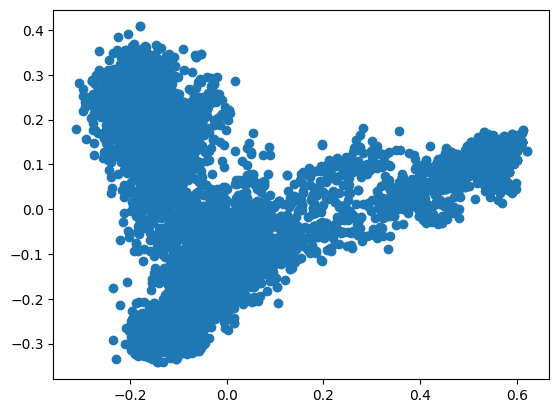

In [62]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Assuming `faiss_index` is your FAISS index object
n = bedrockimage_index.ntotal  # Number of embeddings
d = bedrockimage_index.d  # Dimension of embeddings
X = bedrockimage_index.reconstruct_n(0, n)  # Reconstruct all embeddings

pca = PCA(n_components=2)
X_r = pca.fit_transform(X)

plt.scatter(X_r[:, 0], X_r[:, 1])
plt.show()


## Search indices

In [63]:
def get_item_from_dynamodb(table_name, item_id):
    
    # Get table
    table = dynamodb.Table(table_name)
    
    try:
        # Fetch item by ID
        response = table.get_item(
            Key={
                'id': item_id
            }
        )
    except ClientError as e:
        print(f"An error occurred: {e.response['Error']['Message']}")
        return None
    
    # Return item if found
    return response.get('Item', None)

In [72]:
from collections import defaultdict

def search_image(query_image_url, k=5):
    """
    Search for similar images and texts based on the embedding of a query image.
    
    Parameters:
    - query_image_url (str): The URL of the query image.
    - k (int, optional): The number of top similar items to return. Default is 5.
    
    Returns:
    - list: A list of product IDs for the top k similar items.
    
    """
    query_image_embedding = normalise_embedding(np.array(get_image_embedding(fetch_or_base64_string(query_image_url), bedrock)))
    
    # Search in Faiss indexes
    multi_distances, multi_indices = bedrockmulti_index.search(query_image_embedding.reshape(1, -1), k)
    image_distances, image_indices = bedrockimage_index.search(query_image_embedding.reshape(1, -1), k)
    text_distances, text_indices = bedrocktext_index.search(query_image_embedding.reshape(1, -1), k)
    
    # Retrieve product_ids from indices
    image_product_ids = [global_image_id_to_record[i] for i in image_indices[0]]
    multi_product_ids = [global_image_id_to_record[i] for i in multi_indices[0]]
    try:
        text_product_ids = [global_text_id_to_record[i] for i in text_indices[0]]
    except Exception as e:
        print((text_distances, text_indices))
        raise e
    
    # Initialize a scoring dictionary
    score_dict = defaultdict(float)
    
    # Weighted scoring
    image_weight = 0.5
    text_weight = 0.5
    multi_weight = 0
    
    for i, product_id in enumerate(multi_product_ids):
        score_dict[product_id] += multi_distances[0][i] * multi_weight
        
    for i, product_id in enumerate(image_product_ids):
        score_dict[product_id] += image_distances[0][i] * image_weight
    
    for i, product_id in enumerate(text_product_ids):
        score_dict[product_id] += text_distances[0][i] * text_weight
    
    # Sort by score and take top k results
    sorted_results = sorted(score_dict.items(), key=lambda x: x[1], reverse=True)
    top_results = [item[0] for item in sorted_results[:k]]
    
    tupresults = []
    
    for product_id in top_results:
        item = get_item_from_dynamodb("ProductTable", product_id)
        print(product_id)
        images=item['image']
        tupresults.append((product_id,images))
        description = item['description']
        print(f"Product ID: {product_id}")
        print(f"Description: {description}")
        print(f"Image URL: {images}")
        print("------")
    
    return tupresults


## Set up product desc generation

In [73]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [74]:
from PIL import Image
import matplotlib.pyplot as plt
import requests
from io import BytesIO

def visualize_search_results(query_image, search_results):
    """
    Visualize the search results along with the query image.
    
    Parameters:
    - query_image (str or bytes): The URL or byte content of the query image.
    - search_results (list): A list of product IDs representing the search results.
    - records (list): A list of records containing product information.
    """
    # Display Query Image
    query_img = Image.open(BytesIO(fetch_or_byte(query_image)))
    plt.figure(figsize=(20, 10))
    plt.subplot(1, len(search_results) + 1, 1)
    plt.imshow(query_img)
    plt.title("Query Image")
    plt.axis('off')
    
    # Display Search Results
    for i,result in enumerate(search_results,2):
        response = requests.get(result[1][0])
        img = Image.open(BytesIO(response.content))
        plt.subplot(1, len(search_results) + 1, i)
        plt.imshow(img)
        plt.title(f"ID: {result[0][:8]}")
    
    plt.show()

6129ba900af7db9ada523ba231aa00d7
Product ID: 6129ba900af7db9ada523ba231aa00d7
Description: Key Features of JMD Printed Cushions Cover Printed 40x40cm size Made of Cotton,Specifications of JMD Printed Cushions Cover (Pack of 2, 40 cm*40 cm, Multicolor) General Brand JMD Suitable For Cushions Design Code C05 Type Square Material Cotton Style Code C05 Pattern Printed Color Multicolor Dimensions Height 15 inch / 40 cm Width 15 inch / 40 cm Additional Features Reversible No In the Box Number of Contents in Sales Package Pack of 2 Sales Package Cushion Pillow Cover
Image URL: ['http://img6a.flixcart.com/image/cushion-pillow-cover/k/c/y/c05-c05-jmd-original-imaejkegbw9htmhu.jpeg']
------
66191b4a311b5d9babfc00a71ef97c5b
Product ID: 66191b4a311b5d9babfc00a71ef97c5b
Description: Key Features of JMD Printed Cushions Cover Printed 40x40cm size Made of Cotton,Specifications of JMD Printed Cushions Cover (Pack of 2, 40 cm*40 cm, Multicolor) General Brand JMD Suitable For Cushions Design Code C03 Ty

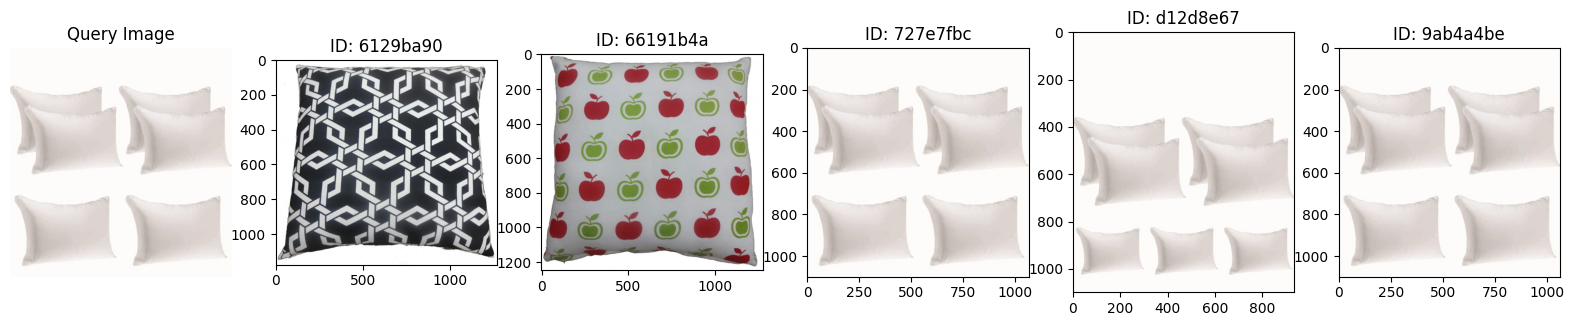

In [75]:

visualize_search_results("http://img5a.flixcart.com/image/pillow/7/u/5/3drfiljdx-6-42x63-jdx-jdx-premium-3d-reliance-fibre-very-soft-1100x1100-imae4a5gxfu3dwzy.jpeg", search_image("http://img5a.flixcart.com/image/pillow/7/u/5/3drfiljdx-6-42x63-jdx-jdx-premium-3d-reliance-fibre-very-soft-1100x1100-imae4a5gxfu3dwzy.jpeg"))

31864c3efb2b4f4197b137124c007378
Product ID: 31864c3efb2b4f4197b137124c007378
Description: Key Features of MERIL Casual Full Sleeve Printed Women's Top Maroon,MERIL Casual Full Sleeve Printed Women's Top Price: Rs. 259 QUALITY PRODUCT FROM HOUSE OF MERIL. MODEL SHOWN IN THE SAMPLE IMAGE IS WEARING A SIZE - L,Specifications of MERIL Casual Full Sleeve Printed Women's Top Top Details Sleeve Full Sleeve Number of Contents in Sales Package Pack of 1 Fabric Cotton Type Top Neck V-Neck General Details Pattern Printed Occasion Casual Ideal For Women's In the Box Top Fabric Care LUKE WARM, DO NOT BLEECH, WASH WITH LIKE COLORS, DO NOT IRON ON PRINT
Image URL: ['http://img5a.flixcart.com/image/top/v/y/j/l-157f-c1-maro-06-meril-xl-original-imaegez3myj8x5vt.jpeg', 'http://img6a.flixcart.com/image/top/v/y/j/l-157f-c1-maro-06-meril-xl-original-imaegez3whgf9yhx.jpeg', 'http://img5a.flixcart.com/image/top/v/y/j/l-157f-c1-maro-06-meril-xl-original-imaegez38agpyzcx.jpeg', 'http://img5a.flixcart.com/imag

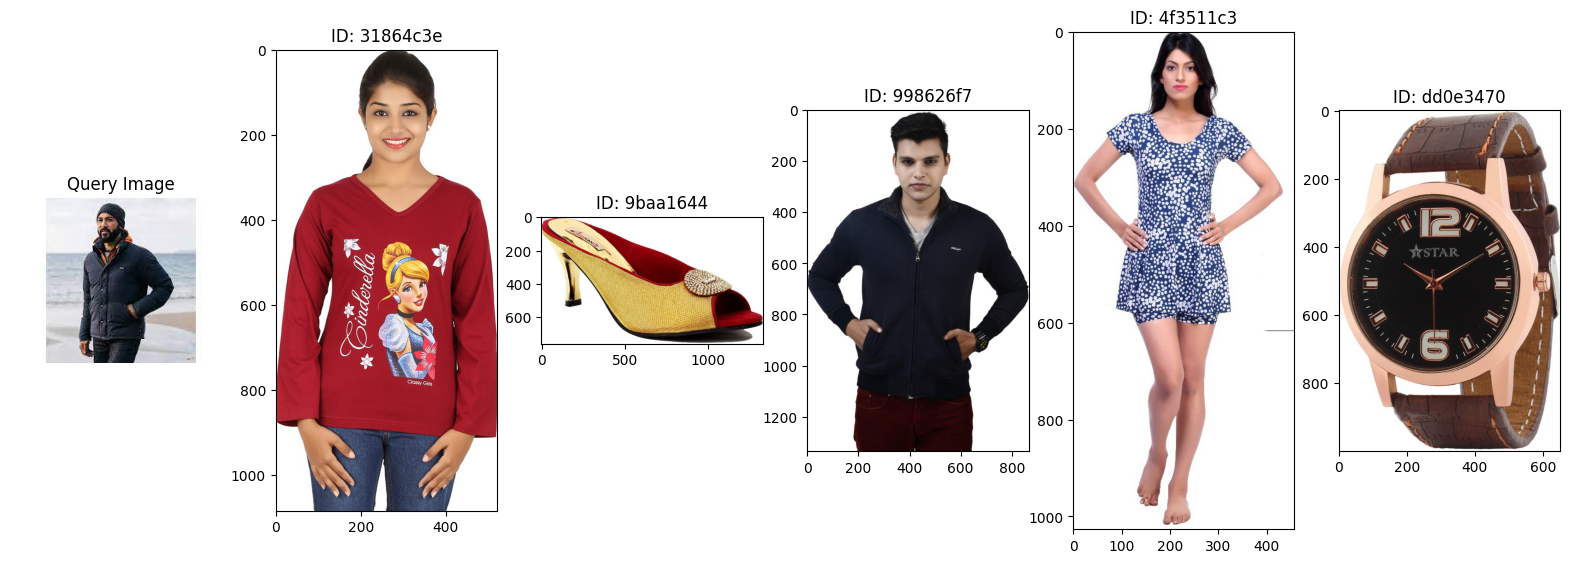

In [76]:
query_image_url ="https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSaxZ42Sj1gIFgZHYNuKNnioNKvCQQFZHUdbR18JY6Q76RYFYnPzbOGwqVRI_AuNkX3GBU&usqp=CAU"
visualize_search_results(query_image_url, search_image(query_image_url))

94421e6bc065763213da73685c89b8f4
Product ID: 94421e6bc065763213da73685c89b8f4
Description: Key Features of medha Women's Multicolor Leggings Multicolor Leggings,medha Women's Multicolor Leggings (Pack of 5) Price: Rs. 999 Premium Quality Slim Fit Comfort Churidar Leggings made with soft cotton & lycra for safe skin and Charismatic Styling. This Cotton Leggings is designed to provide absolute comfort and body fit. Pair it with short or long kurta for modern look. High on style fit and finish this legging is sure to lend you a sophisticated look,Specifications of medha Women's Multicolor Leggings (Pack of 5) In The Box 5 Leggings General Details Number of Contents in Sales Package Pack of 5 Fabric Cotton, Lycra Type Leggings Waistband Elastic Pattern Solid Occasion Casual Ideal For Women's Additional Details Other Features Made by Super Cotton Fabric Care Gentle Machine Wash in Lukewarm Water, Do Not Bleach
Image URL: ['http://img6a.flixcart.com/image/legging-jegging/c/v/e/indi05comb47-m

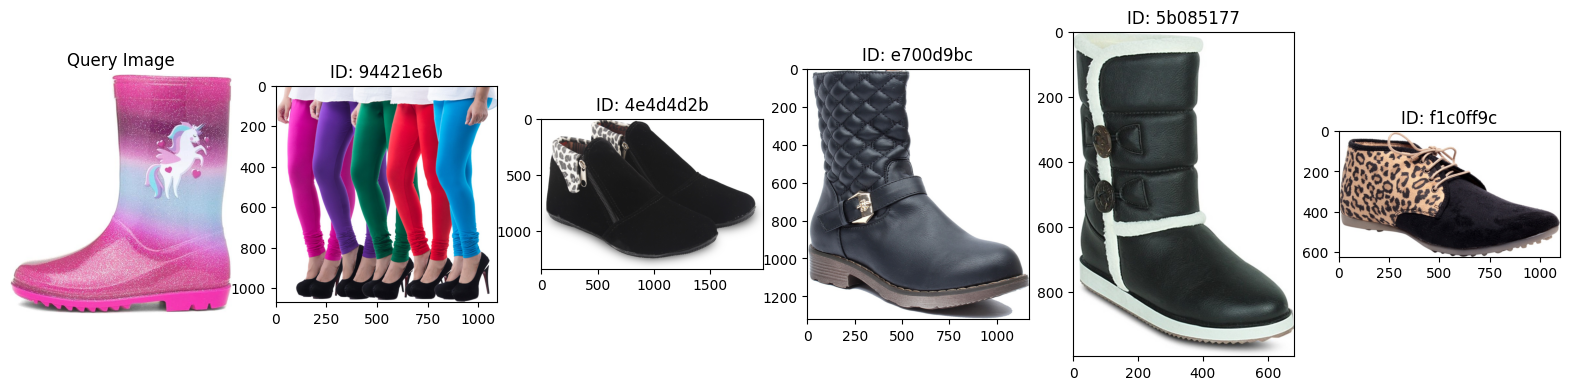

In [77]:
query_image_url ="https://m.media-amazon.com/images/I/71S6Ph8y8GL._AC_UY695_.jpg"
visualize_search_results(query_image_url, search_image(query_image_url))

05324708277dbf2f3e8b55a660e91988
Product ID: 05324708277dbf2f3e8b55a660e91988
Description: Discountgod Men's Checkered Casual Shirt - Buy Blood Red Discountgod Men's Checkered Casual Shirt For Only Rs. 750 Online in India. Shop Online For Apparels. Huge Collection of Branded Clothes Only at Flipkart.com
Image URL: ['http://img5a.flixcart.com/image/shirt/g/x/r/denim-check-discountgod-m-1000x1000-imaebwfkhawzd6gn.jpeg', 'http://img5a.flixcart.com/image/shirt/g/x/r/denim-check-discountgod-m-original-imaebwfkhawzd6gn.jpeg', 'http://img6a.flixcart.com/image/shirt/g/x/r/denim-check-discountgod-l-original-imaebwfzftgrqgcn.jpeg', 'http://img5a.flixcart.com/image/shirt/g/x/r/denim-check-discountgod-m-original-imaebr47sdhg34xj.jpeg', 'http://img6a.flixcart.com/image/shirt/g/x/r/denim-check-discountgod-m-original-imaebwfmqnp9ythp.jpeg', 'http://img6a.flixcart.com/image/shirt/g/x/r/denim-check-discountgod-l-original-imaebwfnwsvakecm.jpeg']
------
0d15b58884366b057241c7ab3a2e2aed
Product ID: 0d15b5

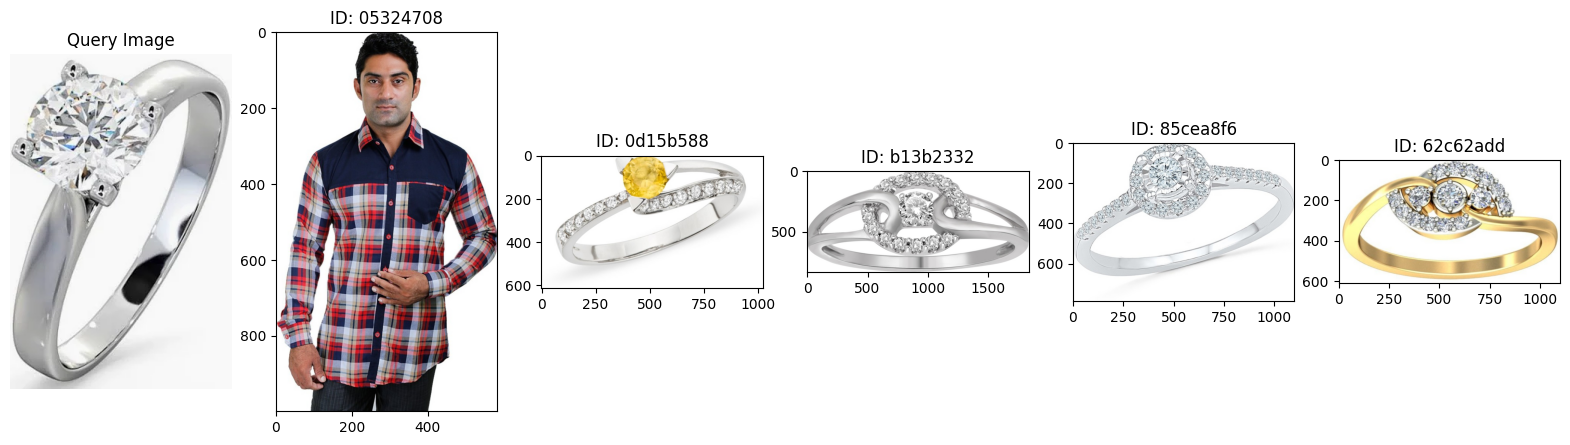

In [78]:
query_image_url = "https://encrypted-tbn3.gstatic.com/shopping?q=tbn:ANd9GcTEJzVGBokOCAhgnFceUDyEUpk9OeO8sh21oCTujgki8RpTDwYnlSeedJ3fTKtFaafg6TYepltQznNXdAItnlV58pHLlEZHo7gRyqsX7raEQmCK3r2jZv1RoYwvUqsP-Y6XDgeqzOY&usqp=CAc"
search_results = search_image(query_image_url)
visualize_search_results(query_image_url, search_results)

In [71]:
visualize_search_results('http://img5a.flixcart.com/image/top/d/v/u/1-1-mg2171-mangosteen-m-original-imaec88gr9r9erd8.jpeg', search_image('http://img5a.flixcart.com/image/top/d/v/u/1-1-mg2171-mangosteen-m-original-imaec88gr9r9erd8.jpeg'))

ValidationException: An error occurred (ValidationException) when calling the InvokeModel operation: 400 Bad Request: Image exceeds max pixels allowed. 

In [ ]:
from PIL import Image
from io import BytesIO

def pil_image_to_byte_array(image, format='JPEG'):
    
    if image.mode == 'P':
        image = image.convert('RGB')
    byte_io = BytesIO()
    image.save(byte_io, format=format)
    byte_array = byte_io.getvalue()
    return byte_array


In [ ]:
from PIL import  ImageEnhance
import requests

def process_image(url):
    """
    Process an image from a given URL to generate a list of augmented images.
    
    Parameters:
    - url (str): The URL of the image to be processed.
    
    Returns:
    - list: A list of byte arrays representing the augmented images.
    
    Augmentations Applied:
    1. Rotation: Rotates the original image by 90, 180, and 270 degrees.
    2. Resolution Change: Resizes the original image to resolutions of (200, 200), (400, 400), and (600, 600).
    
    """
    original_img = Image.open(BytesIO(requests.get(url).content))
    augmented_images = []
    enhancer = ImageEnhance.Color(original_img)
    
    # Rotate image
    for angle in [90, 180, 270]:
        img = original_img.rotate(angle)
        augmented_images.append(pil_image_to_byte_array(img))
    
    # Change resolution
    for resolution in [(200, 200), (400, 400), (600, 600)]:
        img = original_img.resize(resolution, Image.ANTIALIAS)
        augmented_images.append(pil_image_to_byte_array(img))
    return augmented_images


In [ ]:
def get_processed_image_embeddings(image_url, clip_model):
    processed_images = process_image(image_url)
    return (get_image_embedding(image_url, clip_model),[get_image_embedding(img_byte_array, clip_model) for img_byte_array in processed_images])


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def cosine_similarity(a, b):
    """
    Compute the cosine similarity between two vectors.
    
    Parameters:
    - a (numpy.ndarray): The first vector.
    - b (numpy.ndarray): The second vector.
    
    Returns:
    - float: The cosine similarity between the two embeddings.
    
    """
    a = np.reshape(a, -1)
    b = np.reshape(b, -1)
    
    dot_product = np.dot(a, b)
    norm_a = np.linalg.norm(a)
    norm_b = np.linalg.norm(b)
    return dot_product / (norm_a * norm_b)


def compare_embeddings(original_embedding, augmented_embeddings):
    """
    Compare the cosine similarities between an original embedding and a list of augmented image embeddings.
    
    Parameters:
    - original_embedding (numpy.ndarray): The original image embedding.
    - augmented_embeddings (list of numpy.ndarray): List of augmented image embeddings.
    
    Returns:
    - None: Displays a heatmap of cosine similarities.
    
    """
    similarities = np.array([cosine_similarity(normalise_embedding(original_embedding), normalise_embedding(aug_emb)) for aug_emb in augmented_embeddings])
    
    # heatmap
    sns.set(font_scale=1.2)
    ax = sns.heatmap([similarities], annot=True, fmt=".3f", cmap="coolwarm", cbar=True, square=True)
    
    # Additional customization
    ax.set_xticklabels([f'Aug_{i+1}' for i in range(len(augmented_embeddings))])
    ax.set_yticklabels(['Original'])
    ax.set_title('Cosine Similarities between Original and Processed Images')
    
    plt.show()



In [ ]:
def compare_results(url):
    visualize_search_results(url, search_image(url), records)
    [visualize_search_results(img, search_image(img), records) for img in process_image(url)]
    

In [ ]:
processed_image_embeddings = get_processed_image_embeddings("https://www.daals.co.uk/cdn/shop/products/Recline_Angle_912c98ba-0643-4d70-b189-a5667e5f8ae4.png?v=1677155030", clip_model)
len(processed_image_embeddings[1])

In [ ]:
compare_embeddings(processed_image_embeddings[0], processed_image_embeddings[1])

In [ ]:
compare_results("https://www.daals.co.uk/cdn/shop/products/Recline_Angle_912c98ba-0643-4d70-b189-a5667e5f8ae4.png?v=1677155030")

## Clean UP

In [ ]:
clip_model.delete_model()
clip_model.delete_endpoint()

In [ ]:
%cd ~/vs

In [ ]:
!rm -r code
!rm -r $model_id

In [ ]:
def delete_table(table_name):
    table = dynamodb.Table(table_name)
    table.delete()

In [ ]:
!rm flipkart_com-ecommerce_sample.json
!rm flipkart_com-ecommerce_sample.csv

In [ ]:
delete_table('ProductTable')
delete_table('CategoryTable')